# Sistema de recomendação de receitas sustentáveis — Planeat

**Reconstrução reproduzível do projeto**. Este notebook lê somente `recipes.csv` e `orders.csv` da Planeat, analisa os dados e compara modelos simples. Os resultados são calculados novamente na execução, não copiados de apresentações anteriores.

**Como usar:** mantenha `recipes.csv` e `orders.csv` na pasta `dados/` do repositório e o notebook na pasta `notebooks/`. Execute todas as células em ordem a partir da raiz do projeto ou da pasta `notebooks/`. Dependências: `pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib`. A variável `wf` é usada como indicador da base; não assumimos unidade física sem confirmação da fonte.

In [1]:
!git clone https://github.com/Vanessa186578/sistema-recomendacao-receitas-sustentaveis.git
%cd /content/sistema-recomendacao-receitas-sustentaveis

Cloning into 'sistema-recomendacao-receitas-sustentaveis'...
remote: Enumerating objects: 62, done.
remote: Counting objects: 100% (62/62), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 62 (delta 19), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (62/62), 733.40 KiB | 4.07 MiB/s, done.
Resolving deltas: 100% (19/19), done.
/content/sistema-recomendacao-receitas-sustentaveis


In [2]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt

# Funciona ao executar a partir da raiz do repositório ou da pasta notebooks.
BASE = Path.cwd()
if not (BASE / 'dados' / 'recipes.csv').exists():
    BASE = BASE.parent

recipes = pd.read_csv(BASE / 'dados' / 'recipes.csv')
orders = pd.read_csv(BASE / 'dados' / 'orders.csv')
print('Receitas:', len(recipes), '| usuários:', orders.user_id.nunique(), '| registros:', len(orders))
display(recipes.head(3), orders.head(3))

Receitas: 813 | usuários: 551 | registros: 81627


,id,name,ingredients,ingredients_quantity,wf
0,444,Asparagi saltati in padella,"['asparagi', 'olio', 'sale']","['100gr', '5ml', '2gr']",263.25
1,861,Baffo di ombrina scottato in padella,"['maggiorana', 'sale', 'olio', 'ombrina']","['2gr', '1.5gr', '5ml', '150gr']",437.46
2,43,Baffo di salmone scottato in padella,"['sale', 'olio', 'prezzemolo', 'salmone']","['0.75gr', '1.5ml', '2gr', '150gr']",404.53


,actual_name,item_id,planned_at,meal,size,quantity,user_id,order_id
0,Latte accadi senza lattosio Granarolo,325,2020-03-07,breakfast,normal,3,4,5
1,Zucchine trifolate,58,2020-03-07,lunch,normal,4,4,5
2,Ancora uno Frollino con pezzi di cioccolato Tr...,85,2020-03-07,breakfast,normal,1,4,5


## 1. Análise exploratória e tratamento

Valores ausentes nas receitas:
id                      0
name                    0
ingredients             0
ingredients_quantity    0
wf                      0
dtype: int64
Valores ausentes nos pedidos:
actual_name    0
item_id        0
planned_at     0
meal           0
size           0
quantity       0
user_id        0
order_id       0
dtype: int64
IDs de receitas duplicados: 0
Interações com receita válida: 81605 de 81627
Resumo do indicador wf:


,count,mean,std,min,25%,50%,75%,max
wf,813.0,633.052337,926.036645,1.0,183.28,370.22,754.14,15744.95


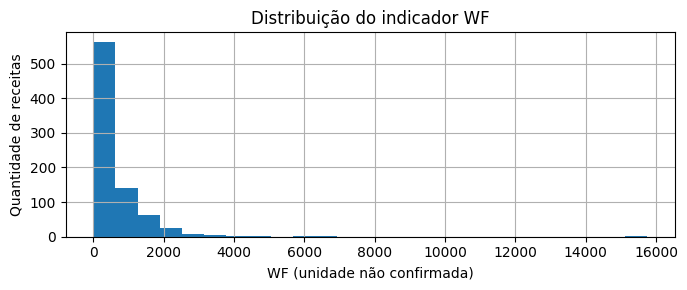

In [3]:
print('Valores ausentes nas receitas:')
print(recipes.isna().sum())
print('Valores ausentes nos pedidos:')
print(orders.isna().sum())
print('IDs de receitas duplicados:', recipes.id.duplicated().sum())
valid = orders[orders.item_id.isin(recipes.id)].copy()
valid['planned_at'] = pd.to_datetime(valid['planned_at'], errors='coerce')
valid = valid.sort_values(['user_id', 'planned_at', 'order_id'], kind='stable')
print('Interações com receita válida:', len(valid), 'de', len(orders))
print('Resumo do indicador wf:')
display(recipes.wf.describe().to_frame().T)
fig, ax = plt.subplots(figsize=(7,3))
recipes.wf.hist(ax=ax, bins=25)
ax.set(title='Distribuição do indicador WF', xlabel='WF (unidade não confirmada)', ylabel='Quantidade de receitas')
plt.tight_layout(); plt.show()

## 2. Divisão treino/teste

Para cada usuário com **pelo menos duas receitas distintas**, reservamos a última receita distinta como teste e usamos as demais interações para treinamento. Assim, cada usuário avaliado possui **uma receita relevante escondida**. A divisão é uma aproximação offline; não equivale a uma avaliação em produção.

In [4]:
heldout = {}
train_parts = []
for uid, group in valid.groupby('user_id', sort=False):
    distinct = group.drop_duplicates('item_id', keep='last')
    if len(distinct) < 2:
        train_parts.append(group)
        continue
    test_item = int(distinct.iloc[-1].item_id)
    heldout[uid] = test_item
    train_parts.append(group[group.item_id != test_item])
train = pd.concat(train_parts, ignore_index=True)
print('Usuários avaliados:', len(heldout), '| interações de treino:', len(train))

Usuários avaliados: 537 | interações de treino: 79686


## 3. Modelos de recomendação

In [5]:
item_ids = recipes.id.to_numpy()
item_index = {int(v):i for i,v in enumerate(item_ids)}
user_ids = np.sort(train.user_id.unique())
user_index = {int(v):i for i,v in enumerate(user_ids)}
rows = train.user_id.map(user_index).to_numpy()
cols = train.item_id.map(item_index).to_numpy()
X = csr_matrix((np.ones(len(train)), (rows,cols)), shape=(len(user_ids),len(item_ids)))
X.data[:] = 1  # presença/ausência da interação, sem contar pedidos repetidos
popularity = np.asarray(X.sum(axis=0)).ravel().astype(float)
# Similaridade entre receitas pelos usuários que interagiram com elas
item_sim = cosine_similarity(X.T, dense_output=True)
np.fill_diagonal(item_sim, 0)
# Similaridade por ingredientes (texto da coluna ingredients)
def parse_ingredients(v):
    try:
        x = ast.literal_eval(v)
        if isinstance(x,list): return ' '.join(str(i).replace(' ', '_') for i in x)
    except (ValueError, SyntaxError): pass
    return str(v)
texts = recipes.ingredients.fillna('').map(parse_ingredients)
content_sim = cosine_similarity(TfidfVectorizer(token_pattern=r'(?u)\b\w+\b').fit_transform(texts))
np.fill_diagonal(content_sim,0)
wf = recipes.wf.to_numpy(dtype=float)
wf_benefit = 1 - (wf - wf.min()) / max(wf.max()-wf.min(),1e-12)

def normalize(a):
    a=np.asarray(a,dtype=float)
    return (a-a.min())/max(a.max()-a.min(),1e-12)

def recommend(uid, model='collaborative', k=10):
    idx=user_index[int(uid)]
    history=X.getrow(idx).indices
    pop=normalize(popularity)
    coll=normalize(item_sim[:,history].sum(axis=1)) if len(history) else pop
    cont=normalize(content_sim[:,history].sum(axis=1)) if len(history) else pop
    scores={'popularity':pop,'collaborative':coll,'content':cont,
            'hybrid':0.5*coll+0.5*cont,
            'sustainable':0.7*coll+0.3*wf_benefit}[model].copy()
    scores[history]=-np.inf  # não recomendar receitas já presentes no treino
    return np.argsort(-scores, kind='stable')[:k]

print('Exemplo de 10 receitas recomendadas:')
u=next(iter(heldout))
display(recipes.iloc[recommend(u,'sustainable')][['name','wf']])

Exemplo de 10 receitas recomendadas:


,name,wf
596,Banana Chiquita 1 pz da circa 200 g,23.70
16,Broccoli saltati in padella,92.18
280,Zucchine grigliate,81.85
50,Fettina di spada scottato in padella,215.36
244,Spaghetto quadrato cacio e pepe,528.51
53,Fettina di tonno rosso scottato in padella,1901.48
146,Minestrone estivo,184.65
243,Spaghetti vongole veraci,754.48
204,Prosciutto e melone,456.20
14,Bresaola con rucola e scaglie di formaggio,880.16


## 4. Avaliação offline

Com uma receita de teste por usuário, `Recall@10` indica a fração de usuários cuja receita reservada apareceu no Top 10. `Precision@10` corresponde ao total de acertos dividido por 10 vezes o número de usuários avaliados. O WF médio é calculado sobre as 10 recomendações de cada usuário.

In [6]:
results=[]
for model in ['popularity','collaborative','content','hybrid','sustainable']:
    hits=0; means=[]
    for uid, item in heldout.items():
        rec_idx=recommend(uid,model)
        hits += int(item_index[item] in rec_idx)
        means.append(wf[rec_idx].mean())
    results.append({'Modelo':model, 'Precision@10 (%)':100*hits/(10*len(heldout)),
                    'Recall@10 (%)':100*hits/len(heldout), 'WF médio Top-10':np.mean(means)})
results_df=pd.DataFrame(results)
display(results_df.round(2))
a=results_df.set_index('Modelo')
wf_reduction=100*(a.loc['collaborative','WF médio Top-10']-a.loc['sustainable','WF médio Top-10'])/a.loc['collaborative','WF médio Top-10']
recall_change=100*(a.loc['sustainable','Recall@10 (%)']-a.loc['collaborative','Recall@10 (%)'])/a.loc['collaborative','Recall@10 (%)']
print(f'Redução relativa WF médio: {wf_reduction:.2f}%')
print(f'Variação relativa Recall@10: {recall_change:.2f}%')
results_df.to_csv(BASE / 'resultados' / 'resultados_modelos.csv', index=False)
print('Tabela salva em resultados/resultados_modelos.csv')


,Modelo,Precision@10 (%),Recall@10 (%),WF médio Top-10
0,popularity,1.79,17.88,556.75
1,collaborative,1.94,19.37,420.04
2,content,0.32,3.17,346.42
3,hybrid,1.27,12.66,378.73
4,sustainable,1.82,18.25,279.78


Redução relativa WF médio: 33.39%
Variação relativa Recall@10: -5.77%
Tabela salva em resultados_modelos.csv


## 5. Limitações e próximos passos

- Esta é uma **nova implementação didática**, não uma recuperação dos códigos perdidos do grupo. Seus números podem diferir dos resultados anteriores.
- O critério sustentável é uma combinação inicial de 70% da pontuação colaborativa e 30% do benefício ambiental normalizado; o peso deve ser calibrado.
- O teste offline usa apenas um item reservado por usuário. Avaliações futuras devem explorar divisões temporais mais rigorosas, mais de um item relevante e diferentes parâmetros.
- O indicador `wf` não foi convertido para litros ou outra unidade, pois isso exige verificar a documentação original.
- O Google Forms da ação extensionista serve para compreender o público; não é usado para treinar este modelo.